# 01 – Data acquisition & EDA
Downloads the UCI Heart Disease archive, cleans it and explores the Cleveland subset.
All plotting code lives in `src/heart_risk/eda.py` so the same figures are regenerated in CI.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]
import os

os.chdir(ROOT)

In [2]:
from heart_risk import config
from heart_risk.data import download_raw, load_raw, clean

download_raw()
raw = load_raw(["cleveland"])
print(raw.shape)
raw.head()

(303, 15)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,source
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,cleveland
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,cleveland
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,cleveland
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,cleveland
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,cleveland


## Raw data quality
The UCI file encodes missing values as `?`. In Cleveland only `ca` (4) and `thal` (2) are affected.

In [3]:
raw.isna().sum()[lambda s: s > 0]

ca      4
thal    2
dtype: int64

In [4]:
raw["num"].value_counts().sort_index()  # 0 = no disease, 1-4 = increasing severity

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

## Cleaning
* binarise `num` → `target`
* invalid codes / impossible zeros → NaN
* drop duplicates

Imputation is **not** done here – it is part of the model pipeline so it is fitted on training folds only.

In [5]:
df = clean(raw)
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## Why only Cleveland?
The other three sites are largely missing `ca`, `thal`, `slope` (and Switzerland has no cholesterol at all). Pooling them would mean imputing >50% of key features.

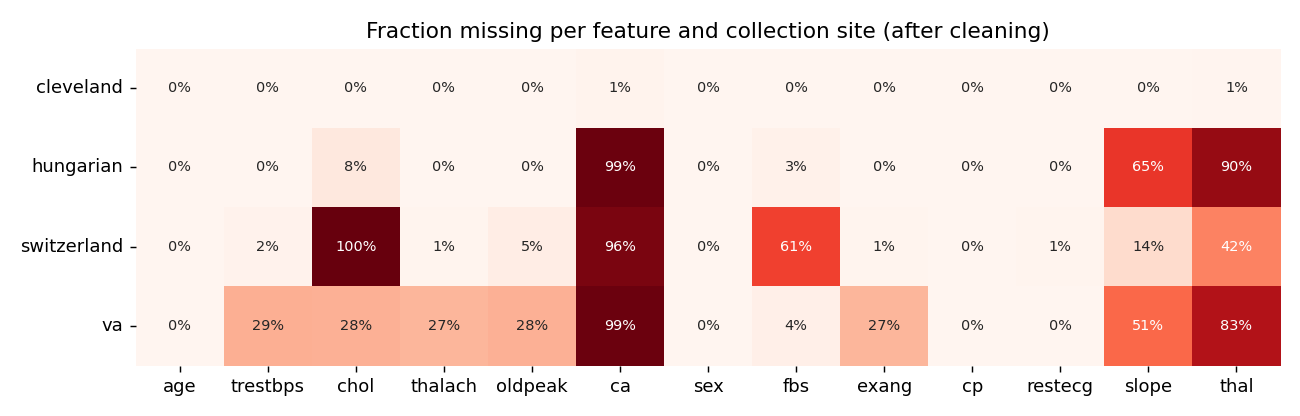

In [6]:
from heart_risk import eda
from IPython.display import Image

p, miss = eda.missingness_by_source()
Image(p)

## Class balance
~46% positive – balanced enough that accuracy is meaningful, but we still track recall/ROC-AUC.

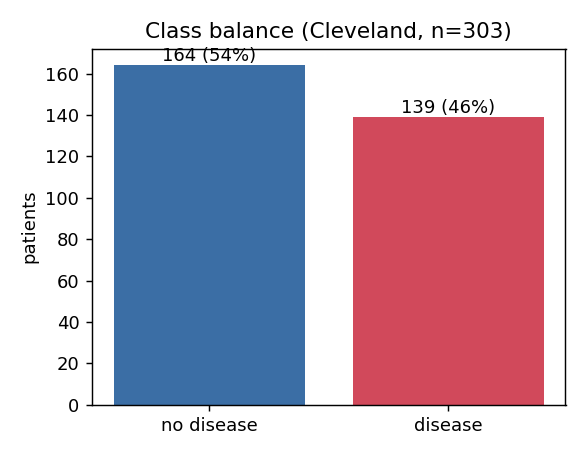

In [7]:
Image(eda.class_balance(df))

## Distributions of numeric features

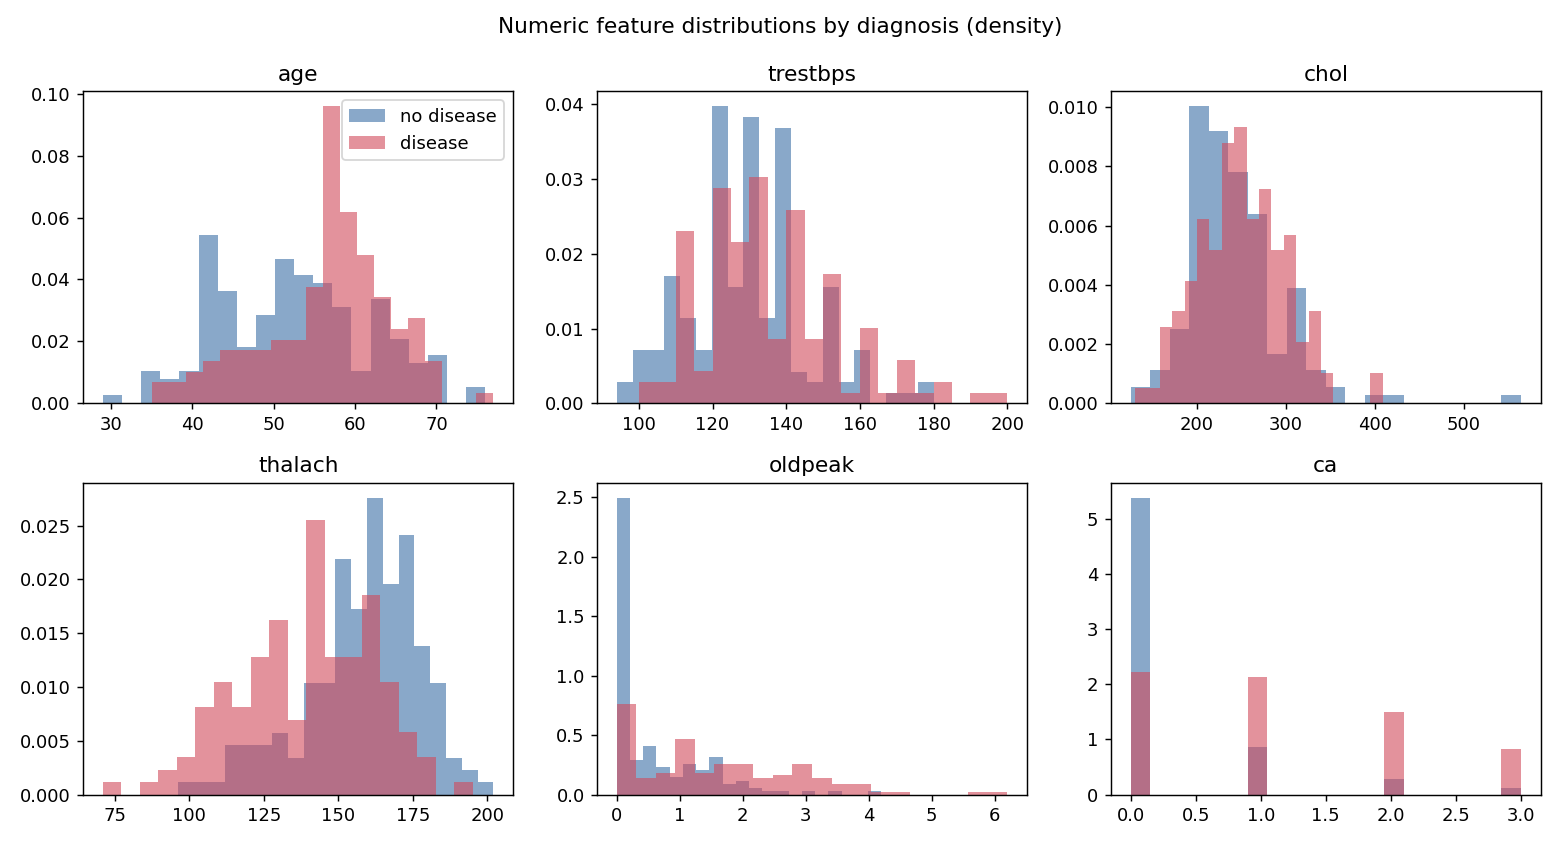

In [8]:
Image(eda.numeric_histograms(df))

Observations: diseased patients reach a **lower max heart rate** (`thalach`), show **larger ST depression** (`oldpeak`) and have **more coloured vessels** (`ca`). Cholesterol and resting BP separate the classes only weakly.

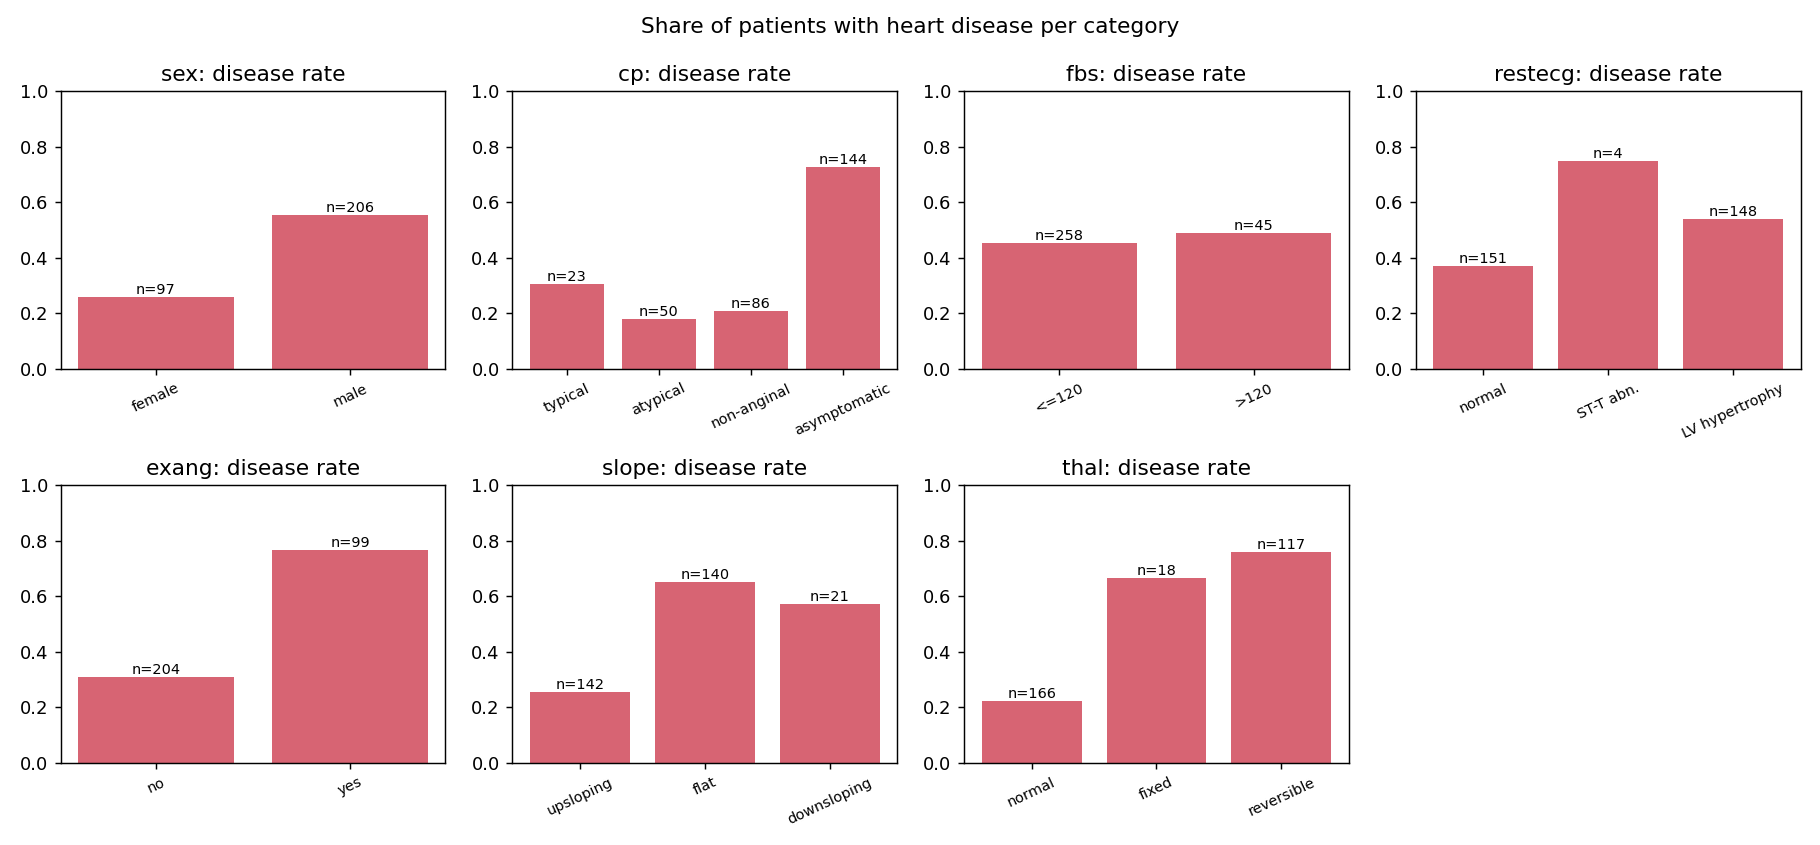

In [9]:
Image(eda.categorical_rates(df))

Asymptomatic chest pain (`cp=4`), exercise-induced angina, a flat ST slope and a reversible thallium defect are each associated with >65% disease prevalence.

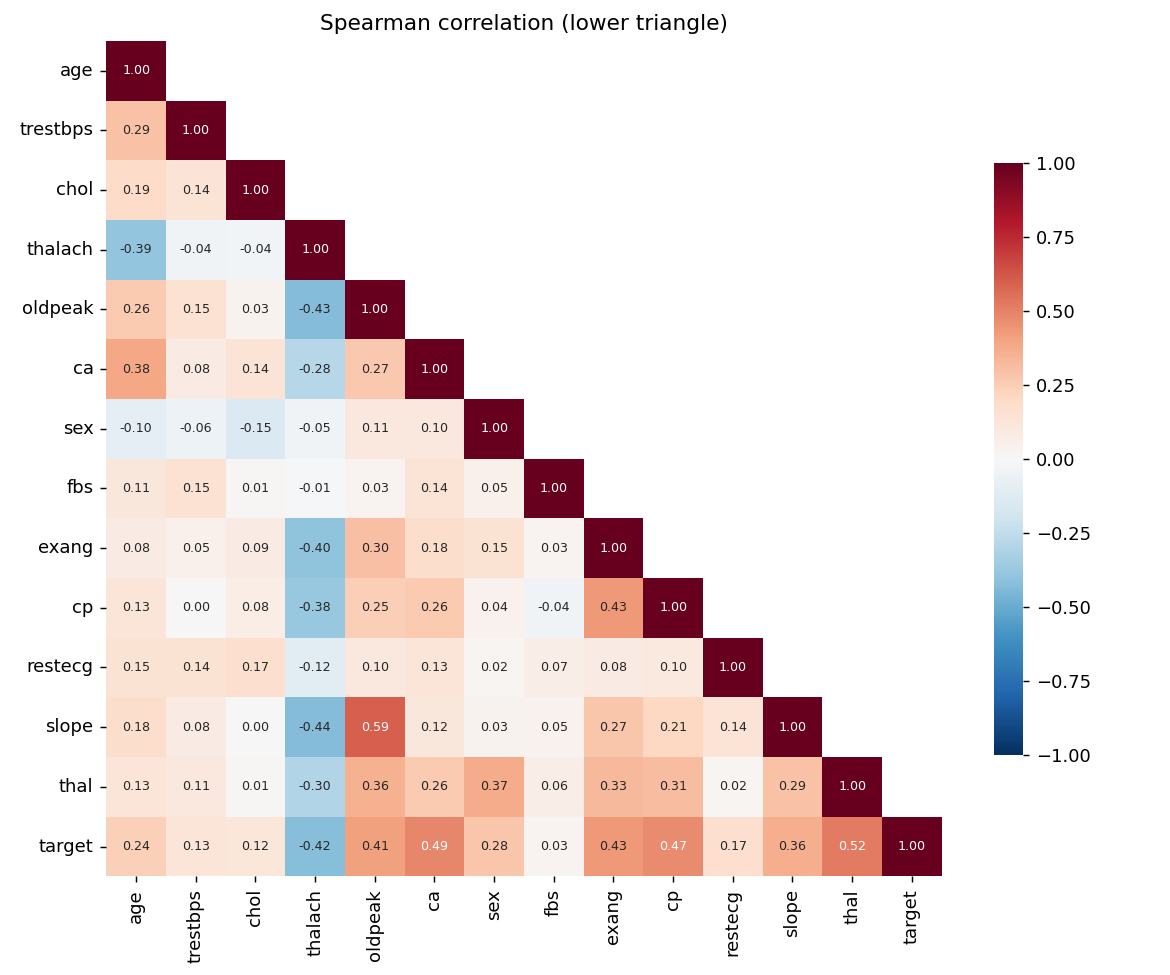

In [10]:
Image(eda.correlation_heatmap(df))

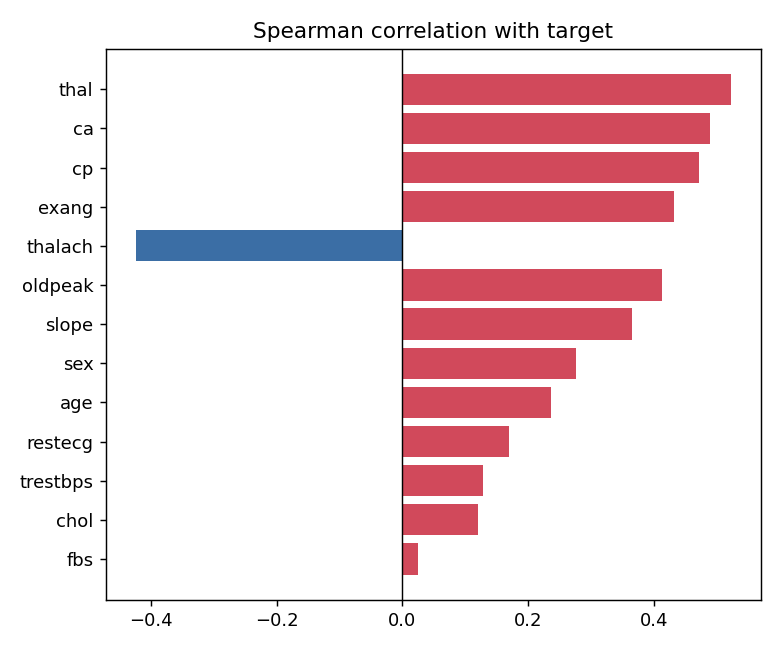

In [11]:
Image(eda.target_correlation(df))

## Feature-engineering motivation
Max heart rate naturally falls with age, so `thalach` is confounded. Normalising by the age-predicted maximum (220 − age) gives a heart-rate-reserve ratio – the basis of the engineered `hr_reserve_ratio` feature.

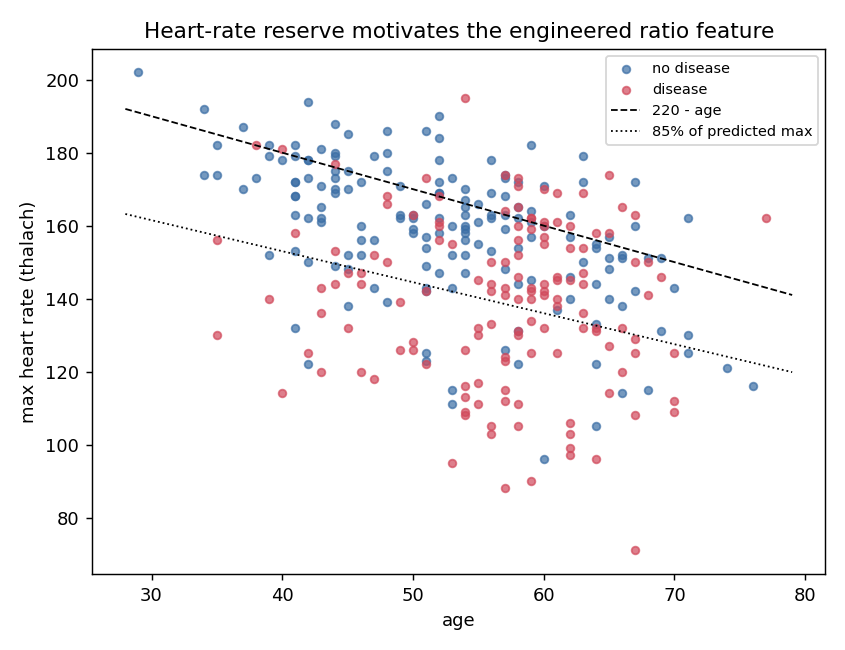

In [12]:
Image(eda.age_vs_thalach(df))

In [13]:
config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
df.to_csv(config.PROCESSED_CSV, index=False)
print("saved", config.PROCESSED_CSV)

saved /Users/bhargava/Downloads/assignment/data/processed/heart_clean.csv
